# Wine Quality: Correlation and Distribution Analysis

## Introduction

This project explores the red wine quality dataset to understand the distribution of wine characteristics and investigate relationships between their chemical properties and quality ratings.

The analysis includes an initial data inspection, a probability mass function (PMF) for wine quality, histograms and cumulative distribution functions (CDFs) for selected numerical features, quantile and interquartile range (IQR) calculations, potential outlier detection, boxplots, and Pearson and Spearman correlation analysis.

The main objectives are to describe the dataset, identify distribution patterns and potential outliers, and examine which chemical properties are most strongly associated with wine quality. The analysis focuses on descriptive statistics and correlation; it does not establish causal relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('winequality-red.csv', sep=';')
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

#### Selecting Appropriate Distribution Analysis Methods

The `quality` variable takes discrete integer values and is therefore suitable for a probability mass function (PMF). The PMF describes the proportion of observations associated with each quality score.

The continuous physicochemical variables, including `alcohol`, `pH`, `residual sugar`, and `fixed acidity`, are examined using histograms, empirical cumulative distribution functions (CDFs), quartiles, and the interquartile range (IQR). These methods help characterize their distributions, identify their central ranges, and detect potential outliers.

Although the dataset contains other numerical features, these four variables are selected for a more detailed distribution analysis.

### Probability Mass Function (PMF)

A probability mass function describes the probability associated with each possible value of a discrete variable. Here, the PMF is calculated for the `quality` variable using normalized value counts.

Multiplying the normalized frequencies by 100 expresses the results as percentages rather than probabilities between 0 and 1. Sorting by quality score makes the distribution easier to interpret in ascending order.

This analysis identifies the most common quality ratings and shows how frequently each rating occurs in the dataset.

In [6]:
# PMF
pmf = df['quality'].value_counts(normalize=True).sort_index()*100
pmf

quality
3     0.625391
4     3.314572
5    42.589118
6    39.899937
7    12.445278
8     1.125704
Name: proportion, dtype: float64

### Visualizing the Quality Distribution

The bar chart displays the percentage of wine samples at each quality score. The height of each bar represents the relative frequency of that score.

The distribution is concentrated around quality scores of 5 and 6, with score 5 being the most frequent. Very low and very high scores occur less often, indicating that the dataset is not evenly distributed across all quality categories.

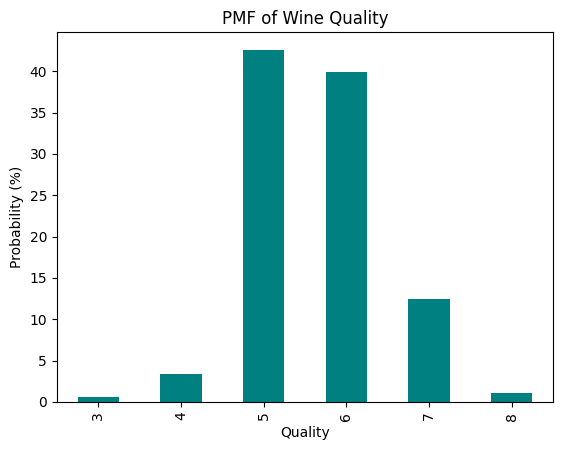

In [7]:
pmf.plot(kind = 'bar', color ='teal')
plt.xlabel('Quality')
plt.ylabel('Probability (%)')
plt.title('PMF of Wine Quality' , fontsize=12)
plt.show()

### Distribution of Continuous Variables

Histograms are used to examine the distributions of alcohol, pH, residual sugar, and fixed acidity. Each histogram groups observations into bins, allowing the frequency and overall shape of a variable's distribution to be observed.

The alcohol values are concentrated mainly around the lower-to-middle part of their observed range, while residual sugar and fixed acidity show right-skewed distributions, with relatively few observations at higher values. The pH distribution is more concentrated within a comparatively narrow range.

These plots help reveal concentration, skewness, spread, and possible extreme values. However, a long tail or a small number of observations at the extremes does not automatically indicate erroneous data.

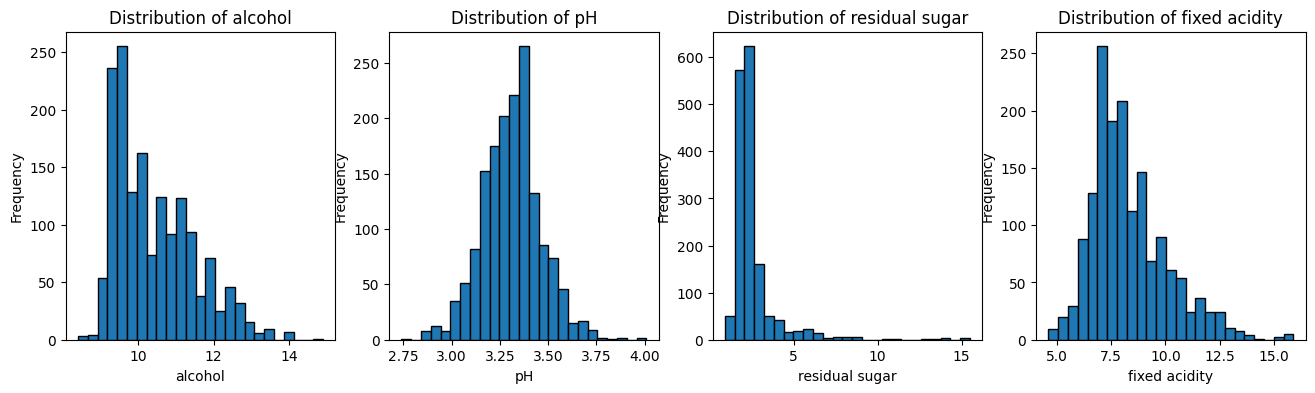

In [8]:
column = ["alcohol", "pH", "residual sugar", "fixed acidity"]

fig, axes = plt.subplots(1,4 , figsize=(16,4))

for ax, col in zip(axes , column):
    ax.hist(df[col] , bins=25 , edgecolor = 'black')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frequency')

plt.show()

###. Empirical Cumulative Distribution Function (CDF)

The empirical CDF represents the proportion of observations less than or equal to each observed value. The data are sorted in ascending order, and each observation is assigned its cumulative proportion.

The CDF complements the histogram by showing how quickly the cumulative proportion increases across a variable's range. For example, it can be used to estimate the proportion of wines with residual sugar below a chosen threshold.

The curve reaches 1.0 at the maximum observed value because all observations are included by that point. Since the variables have different units and scales, their slopes should not be compared directly without considering their respective horizontal-axis scales.

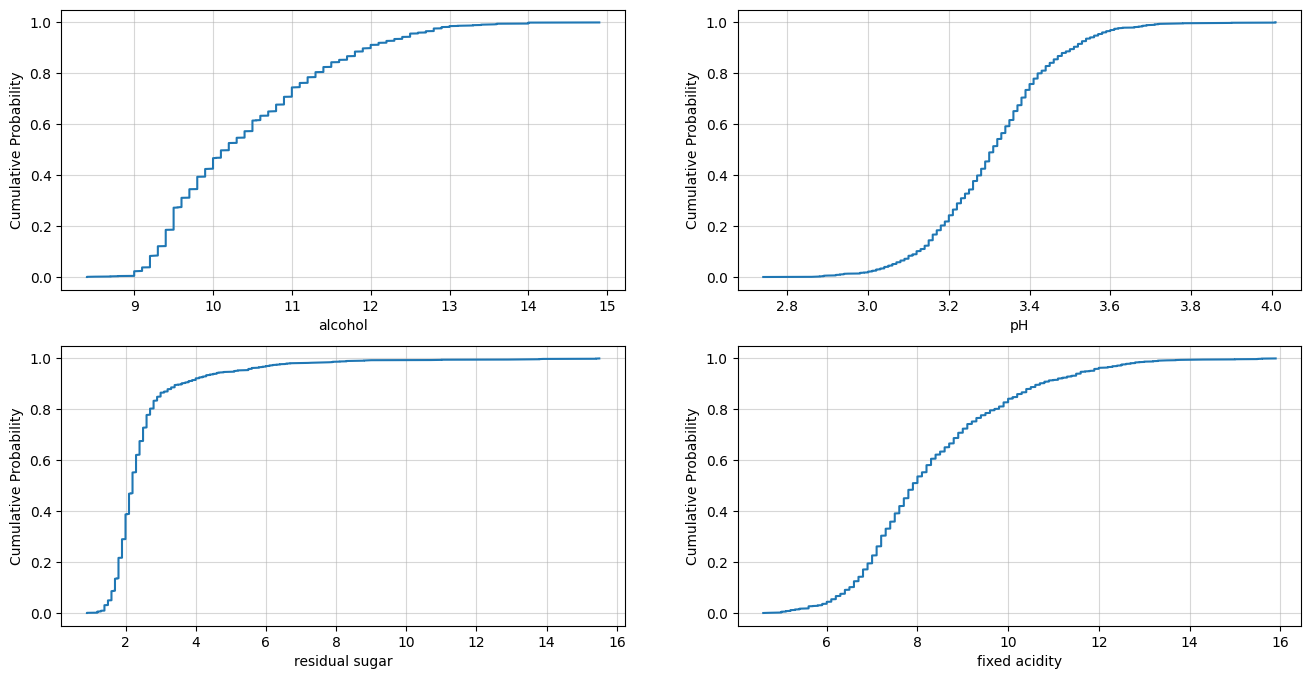

In [9]:
# CDF
fig, axes = plt.subplots(2,2 , figsize=(16,8))
axes = axes.flatten()

for ax, col in zip(axes , column):
    values = np.sort(df[col])
    cdf = np.arange(1, len(values)+1)/len(values)
    ax.plot(values , cdf)
    ax.set_xlabel(col)
    ax.set_ylabel("Cumulative Probability")
    ax.grid(alpha=0.5)

plt.show()

### Quartiles and Interquartile Range (IQR)

The first quartile (Q1) is the 25th percentile, the second quartile (Q2) is the median or 50th percentile, and the third quartile (Q3) is the 75th percentile.

The interquartile range is calculated as:

\[
IQR = Q3 - Q1
\]

The IQR measures the spread of the middle 50% of observations and is less sensitive to extreme values than the full range.

Among the four selected variables, fixed acidity has the largest numerical IQR, while pH has the smallest. Because the variables use different units and scales, their raw IQR values should not be interpreted as directly comparable measures of relative variability.

In [10]:
# Calculate Q1,Q2,Q3 and IQR
for col in column:
    q1 = df[col].quantile(0.25)
    q2 = df[col].quantile(0.5)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1

    print(f'\n{col}')
    print(f"Q1:  {q1:.3f}")
    print(f"Q2:  {q2:.3f}")
    print(f"Q3:  {q3:.3f}")
    print(f"IQR: {iqr:.3f}")


alcohol
Q1:  9.500
Q2:  10.200
Q3:  11.100
IQR: 1.600

pH
Q1:  3.210
Q2:  3.310
Q3:  3.400
IQR: 0.190

residual sugar
Q1:  1.900
Q2:  2.200
Q3:  2.600
IQR: 0.700

fixed acidity
Q1:  7.100
Q2:  7.900
Q3:  9.200
IQR: 2.100


### Detecting Potential Outliers Using the IQR Rule

Potential outliers are identified using the 1.5 × IQR rule. The lower and upper fences are calculated as follows:


$$
\text{Lower Fence} = Q_1 - 1.5 \times IQR
$$

$$
\text{Upper Fence} = Q_3 + 1.5 \times IQR
$$

Any observation below the lower fence or above the upper fence is flagged as a potential outlier.

Residual sugar has the largest number of potential outliers among the four selected variables, accounting for approximately 9.69% of its observations. The corresponding percentages are approximately 0.81% for alcohol, 2.19% for pH, and 3.06% for fixed acidity.

These observations are statistical flags rather than confirmed errors. Extreme values may represent genuine wine samples, so they should not be removed without further investigation or domain-specific justification.

In [11]:
# Check Outliers
#Lower fence = Q1 - 1.5(IQR)
#Upper fence = Q3 + 1.5(IQR)
for col in column:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3-q1

    lower = q1 - 1.5*(iqr)
    upper = q3 + 1.5*(iqr)

    outliers = df[
        (df[col] < lower) | (df[col] > upper)][col]

    print(f"\n{col}")
    print(f"Lower fence: {lower:.3f}")
    print(f"Upper fence: {upper:.3f}")
    print(f"Number of potential outliers: {len(outliers)}")
    print(f"Percentage: {len(outliers) / len(df) * 100:.2f}%")


alcohol
Lower fence: 7.100
Upper fence: 13.500
Number of potential outliers: 13
Percentage: 0.81%

pH
Lower fence: 2.925
Upper fence: 3.685
Number of potential outliers: 35
Percentage: 2.19%

residual sugar
Lower fence: 0.850
Upper fence: 3.650
Number of potential outliers: 155
Percentage: 9.69%

fixed acidity
Lower fence: 3.950
Upper fence: 12.350
Number of potential outliers: 49
Percentage: 3.06%


### Visualizing Distributions and Potential Outliers with Boxplots

Boxplots provide a compact summary of each variable's distribution. The box extends from Q1 to Q3, the line inside the box represents the median, and the whiskers show the range covered by the plotting rule. Individual points beyond the whiskers represent potential outliers.

The boxplots provide a visual comparison of the central spread and highlight observations flagged by the IQR-based rule. Their patterns are consistent with the previous numerical analysis, particularly the presence of more extreme observations in residual sugar.

The appearance of an observation beyond a whisker does not necessarily mean that it is invalid. The boxplots should therefore be interpreted alongside the descriptive statistics and the context of the data.

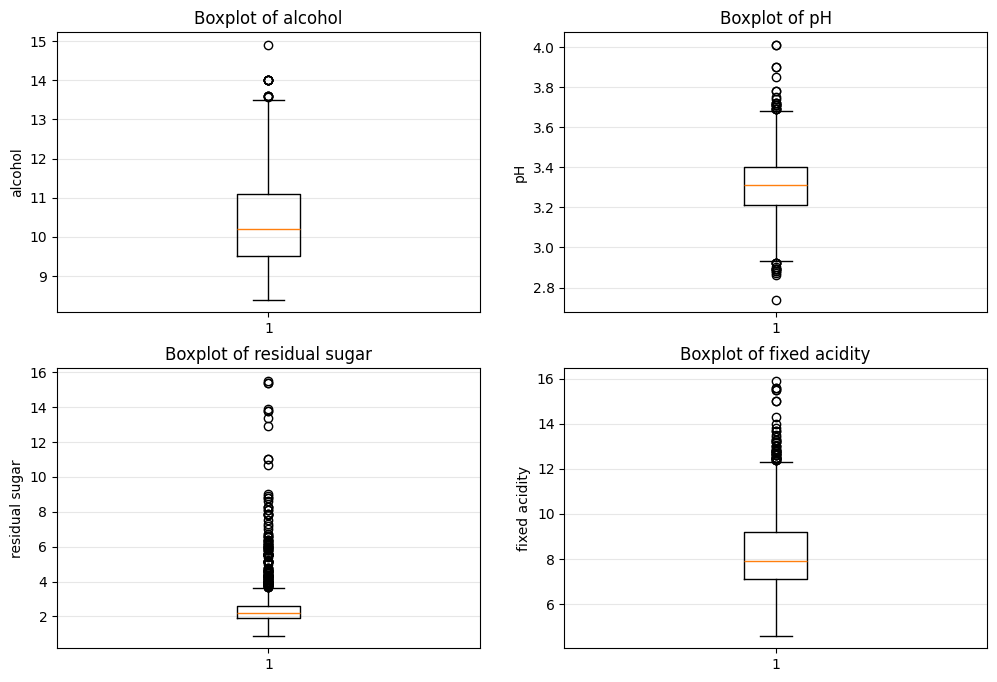

In [19]:
fig, axes = plt.subplots(2,2 , figsize=(12,8))
axes = axes.flatten()

for ax, col in zip(axes , column):
    ax.boxplot(df[col])
    ax.set_title(f'Boxplot of {col}')
    ax.set_ylabel(col)
    ax.grid(axis="y", alpha=0.3)

plt.show()

### Pearson Correlation Analysis

Pearson's correlation coefficient measures the direction and strength of a linear relationship between two numerical variables. Its value ranges from -1 to +1.

A positive coefficient indicates that higher values of one variable tend to be associated with higher values of the other. A negative coefficient indicates an inverse relationship, while a coefficient close to zero indicates a weak linear association.

The Pearson correlation matrix calculates pairwise correlations among the numerical columns. It provides an overview of linear relationships between the physicochemical properties and the wine quality score.

Correlation does not establish causation, and a weak Pearson coefficient does not rule out a nonlinear relationship.

In [23]:
pearson_corr = df.corr(method="pearson", numeric_only=True)
pearson_corr.round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.26,0.67,0.11,0.09,-0.15,-0.11,0.67,-0.68,0.18,-0.06,0.12
volatile acidity,-0.26,1.00,-0.55,0.00,0.06,-0.01,0.08,0.02,0.23,-0.26,-0.20,-0.39
citric acid,0.67,-0.55,1.00,0.14,0.20,-0.06,0.04,0.36,-0.54,0.31,0.11,0.23
residual sugar,0.11,0.00,0.14,1.00,0.06,0.19,0.20,0.36,-0.09,0.01,0.04,0.01
chlorides,0.09,0.06,0.20,0.06,1.00,0.01,0.05,0.20,-0.27,0.37,-0.22,-0.13
free sulfur dioxide,-0.15,-0.01,-0.06,0.19,0.01,1.00,0.67,-0.02,0.07,0.05,-0.07,-0.05
total sulfur dioxide,-0.11,0.08,0.04,0.20,0.05,0.67,1.00,0.07,-0.07,0.04,-0.21,-0.19
density,0.67,0.02,0.36,0.36,0.20,-0.02,0.07,1.00,-0.34,0.15,-0.50,-0.17
pH,-0.68,0.23,-0.54,-0.09,-0.27,0.07,-0.07,-0.34,1.00,-0.20,0.21,-0.06
sulphates,0.18,-0.26,0.31,0.01,0.37,0.05,0.04,0.15,-0.20,1.00,0.09,0.25


### Spearman Rank Correlation Analysis

Spearman's rank correlation measures the strength and direction of a monotonic relationship using the ranks of observations rather than their original numerical values. It ranges from -1 to +1.

Unlike Pearson correlation, Spearman correlation does not require the relationship to be linear. It is also useful when examining associations involving an ordinal variable such as `quality`.

Comparing the Pearson and Spearman matrices helps determine whether relationships are similarly represented by linear correlation and rank-based correlation. Differences between their coefficients may indicate that a relationship is monotonic but not well described by a linear pattern, although scatterplots would be needed to investigate its form more closely.

In [24]:
spearman_corr = df.corr(method="spearman", numeric_only=True)
spearman_corr.round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.28,0.66,0.22,0.25,-0.18,-0.09,0.62,-0.71,0.21,-0.07,0.11
volatile acidity,-0.28,1.00,-0.61,0.03,0.16,0.02,0.09,0.03,0.23,-0.33,-0.22,-0.38
citric acid,0.66,-0.61,1.00,0.18,0.11,-0.08,0.01,0.35,-0.55,0.33,0.10,0.21
residual sugar,0.22,0.03,0.18,1.00,0.21,0.07,0.15,0.42,-0.09,0.04,0.12,0.03
chlorides,0.25,0.16,0.11,0.21,1.00,0.00,0.13,0.41,-0.23,0.02,-0.28,-0.19
free sulfur dioxide,-0.18,0.02,-0.08,0.07,0.00,1.00,0.79,-0.04,0.12,0.05,-0.08,-0.06
total sulfur dioxide,-0.09,0.09,0.01,0.15,0.13,0.79,1.00,0.13,-0.01,-0.00,-0.26,-0.20
density,0.62,0.03,0.35,0.42,0.41,-0.04,0.13,1.00,-0.31,0.16,-0.46,-0.18
pH,-0.71,0.23,-0.55,-0.09,-0.23,0.12,-0.01,-0.31,1.00,-0.08,0.18,-0.04
sulphates,0.21,-0.33,0.33,0.04,0.02,0.05,-0.00,0.16,-0.08,1.00,0.21,0.38


### Comparing Pearson and Spearman Correlation Heatmaps

The two heatmaps display the Pearson and Spearman correlation coefficients using a shared color scale from -1 to +1. Red shades represent positive correlations, blue shades represent negative correlations, and colors near the center represent coefficients closer to zero. The numerical annotations provide the exact coefficients rounded to two decimal places.

Several relationships stand out in both matrices. Fixed acidity has a negative correlation with pH and positive correlations with citric acid and density. Free sulfur dioxide and total sulfur dioxide are positively correlated, with a stronger association in the Spearman matrix.

When examining correlations with wine quality, alcohol has the strongest positive association among the features considered, with a Spearman coefficient of approximately 0.48. Sulphates also show a positive association, while volatile acidity has a negative association of approximately -0.38. The Pearson correlation between quality and sulphates is weaker, at 0.25, compared with its Spearman coefficient of 0.38.

These results describe associations in this dataset; they do not demonstrate that any individual chemical property causes a change in wine quality.

In [28]:
import seaborn as sns

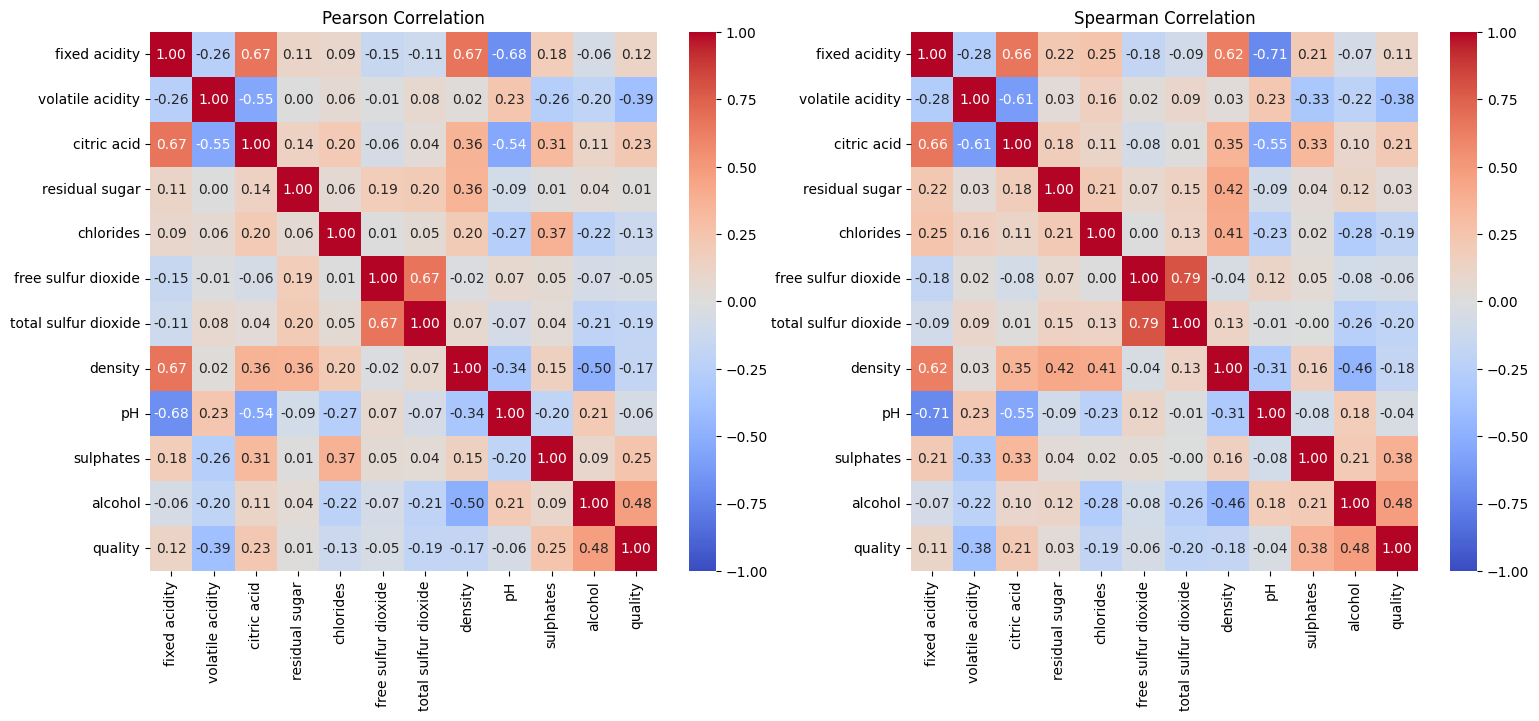

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[0]
)
axes[0].set_title('Pearson Correlation')

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1]
)
axes[1].set_title('Spearman Correlation')
plt.show()

# Conclusion

This project explored the distributions of selected physicochemical properties in the red wine quality dataset and examined their relationships with wine quality.

The PMF analysis showed that quality scores of 5 and 6 account for most observations, with score 5 being the most frequent. Histograms and CDFs provided complementary views of the distributions of alcohol, pH, residual sugar, and fixed acidity. The quartile and IQR analysis summarized their central ranges, while the IQR rule identified potential outliers, particularly in residual sugar. These observations were retained as potential outliers rather than automatically treated as errors.

The correlation analysis revealed several notable associations. Alcohol had the strongest positive correlation with quality among the examined features, with a Spearman coefficient of 0.48. Sulphates showed a positive association with quality, while volatile acidity showed a negative association of -0.38. Pearson and Spearman coefficients differed for some features, highlighting the value of examining both linear and rank-based relationships.

Overall, the analysis demonstrates how descriptive statistics, distribution plots, outlier detection, and correlation heatmaps can be combined to understand a dataset. However, correlation alone cannot establish causality, and further analysis would be required to build and evaluate a predictive model of wine quality.